# Page: `set_input_as_handled()` in the shortcuts plugin

```gdscript
if key.physical_keycode == KEY_RIGHT: bottom_dock.select_next_available()
else: bottom_dock.select_previous_available()
get_viewport().set_input_as_handled()
```

That last line marks the key event as **consumed**. The plugin sees every key first, in `_input`; a consumed event is not passed on, so the editor's own shortcut for the same keys never runs.

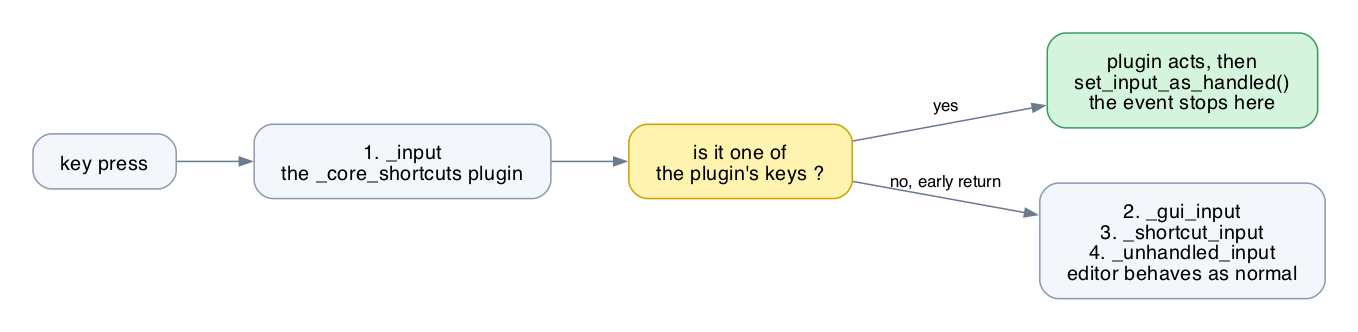

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  press  [label="key press"];
  plugin [label="1. _input\nthe _core_shortcuts plugin"];
  match  [label="is it one of\nthe plugin's keys ?", fillcolor="#fff3b0", color="#c9a400"];
  mine   [label="plugin acts, then\nset_input_as_handled()\nthe event stops here", fillcolor="#d4f4dd", color="#3c9a5f"];
  later  [label="2. _gui_input\n3. _shortcut_input\n4. _unhandled_input\neditor behaves as normal"];
  press -> plugin -> match;
  match -> mine  [label="yes"];
  match -> later [label="no, early return"];
}
```

</details>

| Order | Stage | Who uses it | Sees a handled event ? |
|---|---|---|---|
| 1 | `_input` | this plugin | yes, it is the one handling it |
| 2 | `_gui_input` | the focused control, e.g. the code editor | no |
| 3 | `_shortcut_input` | editor shortcuts, e.g. script history back / forward | no |
| 4 | `_unhandled_key_input`, `_unhandled_input` | whatever is left | no |
| every frame | `_process` | per-frame logic, e.g. animation | never receives events at all |
| every physics tick | `_physics_process` | movement and collisions | never receives events at all |

- **Plugin key, line present:** only the plugin's action happens.
- **Plugin key, line removed:** the plugin's action **and** the editor's default action both happen.
- **Any other key:** early `return` before the line, so the editor behaves as normal.

**`_process` and `_physics_process` are not input stages.** Godot has no `_input_process` or `_input_physics`. These two run on a timer (every frame, every physics tick) whether or not a key was pressed, and are handed only `delta`, never the event.

Code in them can still *ask* about keys, e.g. `Input.is_key_pressed(KEY_F11)`. That reads the keyboard's current state, which `set_input_as_handled()` does not change: a handled key still reads as pressed there.
